# EVCharge Intelligence — plotting code and inline charts

Member 2: **Sagar K, PES2UG24CS424**. This companion notebook shows the code behind all seven temporal visualizations and embeds actual chart outputs. It recalculates and validates through `demand_analysis.py`, compares against the verified Phase 2 summaries, and draws from those summaries. No saved chart images are read or written.

Research motivation: Baek, K., Lee, E., & Kim, J. (2024), [*A dataset for multi-faceted analysis of electric vehicle charging transactions*](https://doi.org/10.1038/s41597-024-02942-9), Scientific Data, 11, 262. Temporal inspection is a methodological idea; the paper's dataset and results are separate from ours. Session starts differ from connection/coupling profiles; calendar normalization and our index are project choices.

Source status: **shared by team member; original source and licence unverified**. Collection methodology and timezone are unverified. This notebook preserves the original linked-figure notebook and CLI exports.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

current = Path.cwd().resolve()
ROOT = current if (current / "src/demand_analysis.py").is_file() else current.parent
if not (ROOT / "src/demand_analysis.py").is_file():
    raise RuntimeError("Run from the repository root or notebooks directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data_preparation import file_hash
from src.demand_analysis import analyze_sessions, WEEKDAYS
from src.demand_visualization import (
    load_analysis, style_axis, finish_figure, month_ticks,
    BLUE, ORANGE, GREEN, ENERGY_NOTE,
)

# Activate inline rendering after imports; the reusable CLI module uses Agg.
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib_inline.backend_inline import set_matplotlib_formats
import seaborn as sns

set_matplotlib_formats("png")  # One normal-resolution output, without retina/SVG duplicates.
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
                     "axes.titlesize": 12, "font.family": "DejaVu Sans"})
sns.set_style("white")

summary_dir = ROOT / "outputs/demand"
protected = [ROOT / "data/processed/charging_sessions.csv",
             *sorted(summary_dir.glob("*.csv")), summary_dir / "analysis_summary.json"]
protected_hashes = {path: file_hash(path) for path in protected}
tables, summary = load_analysis(summary_dir)
cleaned = pd.read_csv(protected[0], dtype=str, keep_default_na=False)
recomputed_tables, recomputed_summary = analyze_sessions(cleaned)
for name, saved_table in tables.items():
    pd.testing.assert_frame_equal(saved_table, recomputed_tables[name],
                                  check_dtype=False, rtol=1e-10, atol=1e-6)
assert recomputed_summary["reconciliation"]["all_passed"]
del cleaned, recomputed_tables
print(f"Validated {summary['input_session_count']:,} sessions and all seven summary tables.")


def show_inline(figure, note):
    """Reuse layout helpers, display once, then close to prevent duplicate outputs."""
    try:
        finish_figure(figure, note)
        display(figure)
    finally:
        plt.close(figure)

Validated 200,000 sessions and all seven summary tables.


## 1. Hourly starts

**Question:** Do session starts concentrate in particular hours? **Metric:** average session starts per calendar day in each start hour. All 24 hours use the same 730-date denominator. The dashed reference is the mean of the 24 hourly averages; labels report extreme ties without changing the zero-based scale.

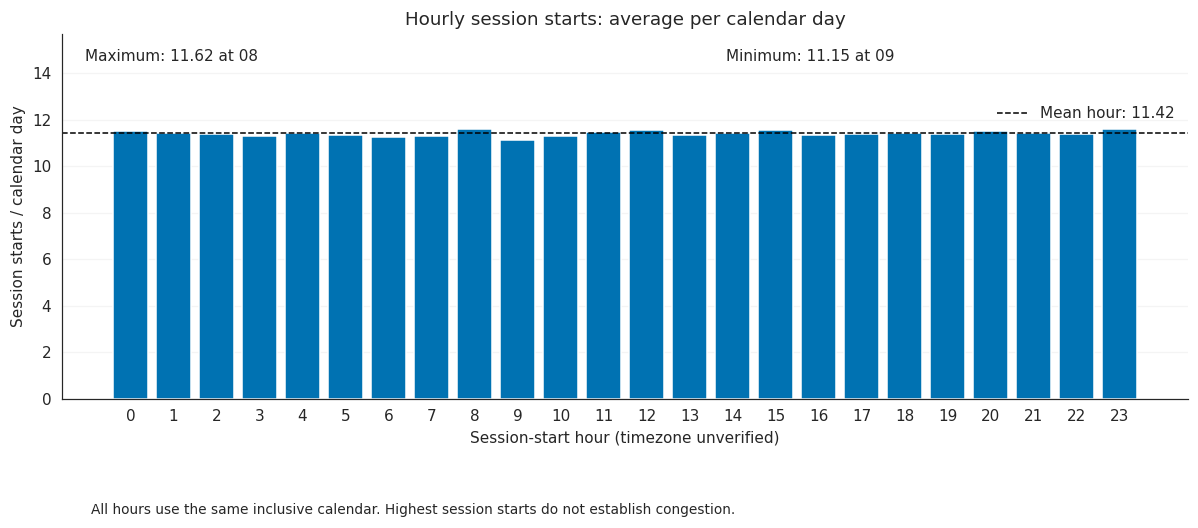

In [2]:
hourly = tables["hourly_demand"]
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(hourly.Charging_Hour, hourly.avg_sessions_per_day, color=BLUE)
mean_hour = hourly.avg_sessions_per_day.mean()
ax.axhline(mean_hour, color="black", linestyle="--", linewidth=1,
           label=f"Mean hour: {mean_hour:.2f}")
for label, value, position in [
    ("Maximum", hourly.avg_sessions_per_day.max(), 0.02),
    ("Minimum", hourly.avg_sessions_per_day.min(), 0.59),
]:
    tied_hours = hourly.loc[hourly.avg_sessions_per_day.eq(value), "Charging_Hour"]
    hours_text = ", ".join(f"{hour:02d}" for hour in tied_hours)
    ax.text(position, 0.96, f"{label}: {value:.2f} at {hours_text}",
            transform=ax.transAxes, va="top")
ax.set_xticks(range(24))
ax.set_ylim(0, hourly.avg_sessions_per_day.max() * 1.35)
ax.set_xlabel("Session-start hour (timezone unverified)")
ax.set_title("Hourly session starts: average per calendar day")
style_axis(ax, "Session starts / calendar day")
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.84))
show_inline(fig, "All hours use the same inclusive calendar. Highest session starts do not establish congestion.")

**Findings and limitations:** Hourly demand is **nearly uniform**: relative index 0.97668–1.01760. Hour 08 is highest (8,480 starts; 11.62/day), and hour 09 lowest (8,139; 11.15/day), around a mean of 11.42/hour/day. These are session-start counts, not simultaneous occupancy or proven congestion; no statistical significance is claimed.

## 2. Daily starts and smoothing

**Question:** How does recorded daily demand vary over the calendar? **Metric:** session starts/date and a trailing 7-day mean. The existing analysis supplies every date, including zero-session dates. Smoothing requires seven observations (`min_periods=7`); the initial six means remain missing.

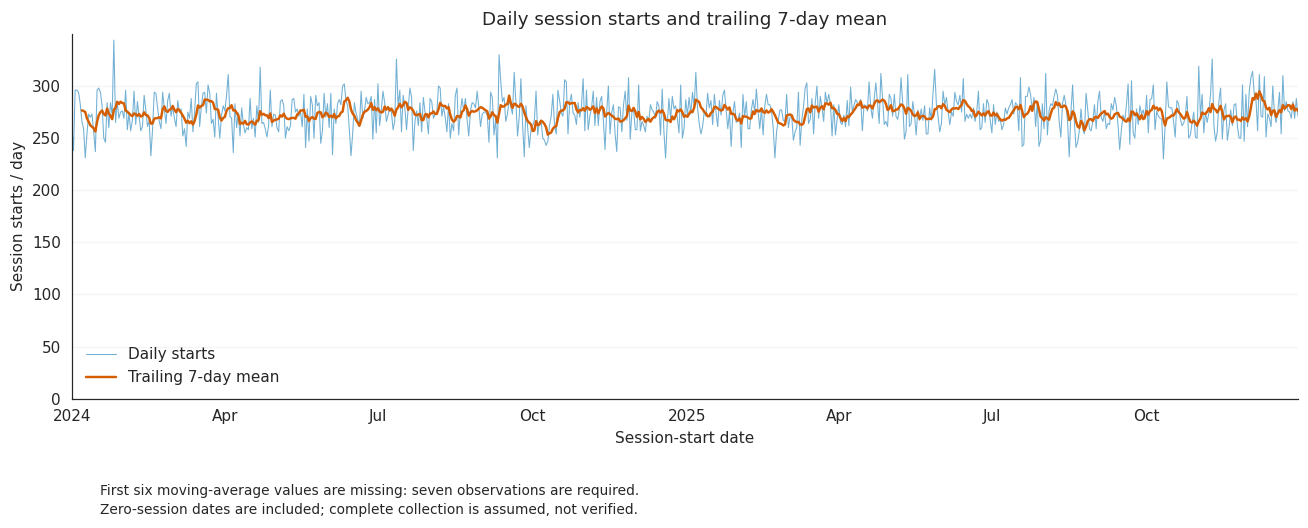

In [3]:
daily = tables["daily_demand"]
dates = pd.to_datetime(daily.Charging_Date, format="%Y-%m-%d")
# This is display smoothing of an existing summary, not session aggregation.
trailing_mean = daily.session_count.rolling(window=7, min_periods=7).mean()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dates, daily.session_count, color=BLUE, linewidth=0.7, alpha=0.55,
        label="Daily starts")
ax.plot(dates, trailing_mean, color=ORANGE, linewidth=1.6, label="Trailing 7-day mean")
locator = mdates.AutoDateLocator(minticks=5, maxticks=9)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.set_xlim(dates.min(), dates.max())
ax.set_xlabel("Session-start date")
ax.set_title("Daily session starts and trailing 7-day mean")
style_axis(ax, "Session starts / day")
ax.legend(frameon=False, loc="lower left")
show_inline(fig, "First six moving-average values are missing: seven observations are required.\nZero-session dates are included; complete collection is assumed, not verified.")

**Findings and limitations:** Daily starts range from 230 on 11 October 2025 to 344 on 26 January 2024. The represented range is 1 January 2024–30 December 2025. Timestamp coverage does not verify uptime or complete first/last-day observation; the variation does not identify causes or a sustained trend.

## 3. Weekdays and weekends

**Question:** Do average starts differ across calendar day types? **Metric:** starts divided by the number of dates belonging to each weekday or weekday/weekend group, not by all dates.

For example, three starts across two Fridays yield 1.5/Friday, while two starts on one Saturday yield 2/Saturday. Raw totals alone obscure unequal coverage. Both panels use the same vertical scale.

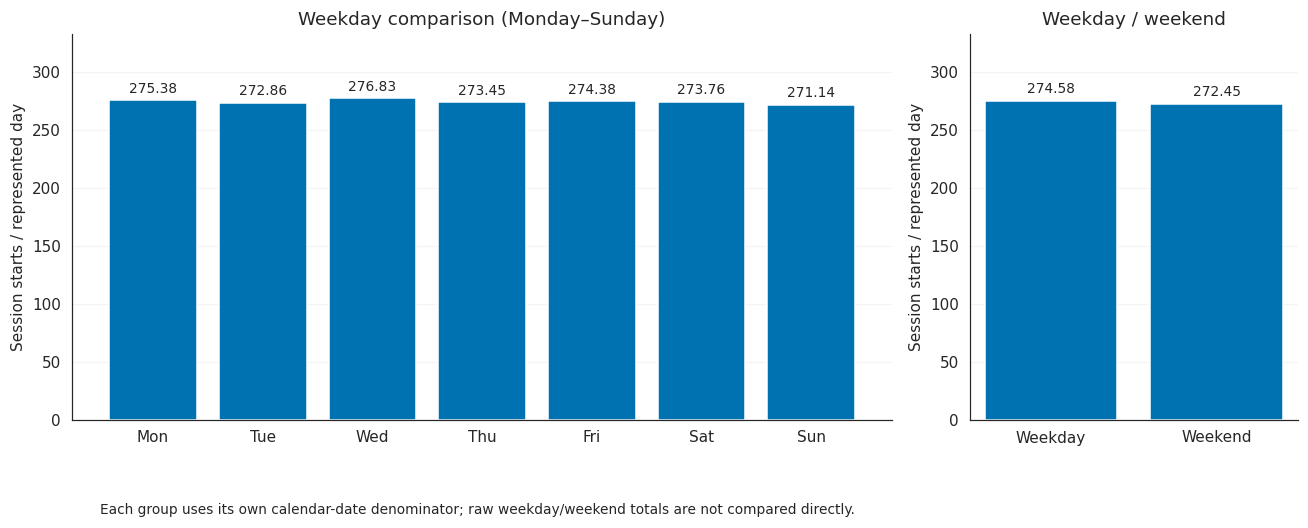

In [4]:
weekday = tables["weekday_demand"]
weekend = tables["weekday_weekend_demand"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [2.5, 1]})
for ax, group, labels in [
    (axes[0], weekday, weekday.Weekday_Name.str[:3]),
    (axes[1], weekend, weekend.Day_Type),
]:
    bars = ax.bar(labels, group.avg_sessions_per_day, color=BLUE)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
    style_axis(ax, "Session starts / represented day")
ceiling = max(weekday.avg_sessions_per_day.max(), weekend.avg_sessions_per_day.max()) * 1.2
for ax in axes:
    ax.set_ylim(0, ceiling)
axes[0].set_title("Weekday comparison (Monday–Sunday)")
axes[1].set_title("Weekday / weekend")
show_inline(fig, "Each group uses its own calendar-date denominator; raw weekday/weekend totals are not compared directly.")

**Findings and limitations:** Weekdays average 274.58 starts/day across 522 dates; weekends average 272.45 across 208 dates. The difference is 2.13/day (about 0.78% relative to weekends). Wednesday is highest at 276.83 and Sunday lowest at 271.14 per represented day. This is a descriptive comparison, not evidence of a causal weekday effect or significance.

## 4. Weekday–hour demand

**Question:** Is there a distinct day–hour concentration of starts? **Metric:** average starts in a weekday–hour cell divided by the number of that weekday's dates. Reshape the verified 168-row table without aggregating sessions again. A sequential color scale starts at zero.

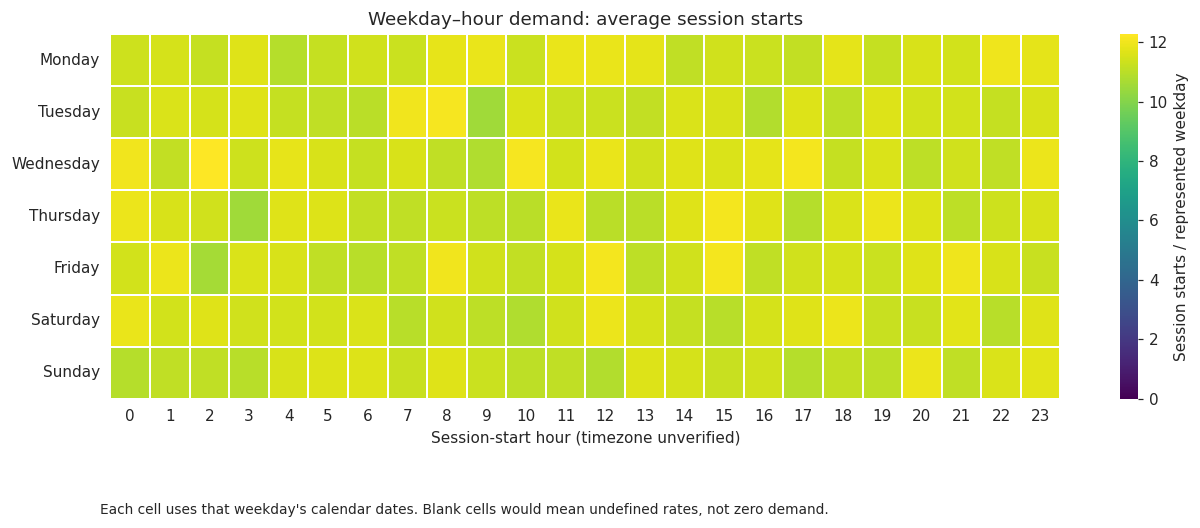

In [5]:
day_hour = tables["day_hour_demand"]
heatmap_values = day_hour.pivot(index="Weekday_Index", columns="Charging_Hour",
                               values="avg_sessions_per_day").reindex(index=range(7), columns=range(24))
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(heatmap_values, cmap="viridis", vmin=0,
            vmax=max(1, heatmap_values.max().max()), linewidths=0.3, ax=ax,
            cbar_kws={"label": "Session starts / represented weekday"})
ax.set_yticklabels(WEEKDAYS, rotation=0)
ax.set_ylabel("")
ax.set_xlabel("Session-start hour (timezone unverified)")
ax.set_title("Weekday–hour demand: average session starts")
show_inline(fig, "Each cell uses that weekday's calendar dates. Blank cells would mean undefined rates, not zero demand.")

**Findings and limitations:** Wednesday 02 is highest (12.27 starts per represented Wednesday) and Tuesday 09 lowest (10.52 per represented Tuesday). No congestion threshold is assigned. Starts do not describe connection/coupling profiles or active charging occupancy.

## 5. Monthly demand

**Question:** How do calendar-normalized starts compare across year-months? **Metric:** starts/represented day, keeping each year-month separate. Asterisks and hatching identify partial boundary-month coverage; they do not mean missing measurements.

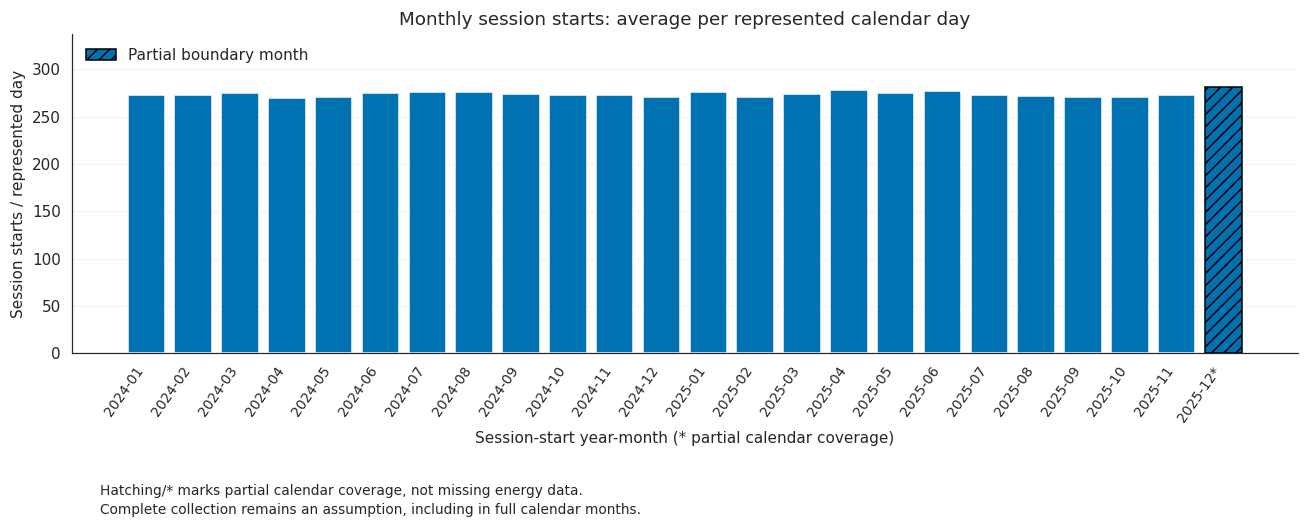

In [6]:
monthly = tables["monthly_demand"]
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(range(len(monthly)), monthly.avg_sessions_per_day, color=BLUE)
for bar, is_partial in zip(bars, monthly.is_partial_boundary_month):
    if is_partial:
        bar.set_hatch("///")
        bar.set_edgecolor("black")
month_ticks(ax, monthly)
style_axis(ax, "Session starts / represented day")
ax.set_ylim(0, monthly.avg_sessions_per_day.max() * 1.2)
ax.set_title("Monthly session starts: average per represented calendar day")
ax.legend(handles=[Patch(facecolor=BLUE, edgecolor="black", hatch="///",
                          label="Partial boundary month")], frameon=False, loc="upper left")
show_inline(fig, "Hatching/* marks partial calendar coverage, not missing energy data.\nComplete collection remains an assumption, including in full calendar months.")

**Findings and limitations:** Monthly demand ranges from 270.00/day in April 2024 to 281.13/day in December 2025. December covers only 1–30 December (30/31 dates). Among full calendar months, April 2025 is highest at 278.83/day. Neither seasonality nor sustained growth is established.

## 6. Recorded energy associated with session-start periods

**Question:** How does recorded energy associated with starts vary by hour and month? **Metric:** valid recorded energy (kWh) per represented calendar day. Baseline retains all finite nonnegative measurements, including zero. Missing/invalid energy is not converted to zero or allowed to remove demand rows.

Whole session energy is assigned to its start period, even for cross-day/month sessions. These are not measured hourly electricity-load profiles.

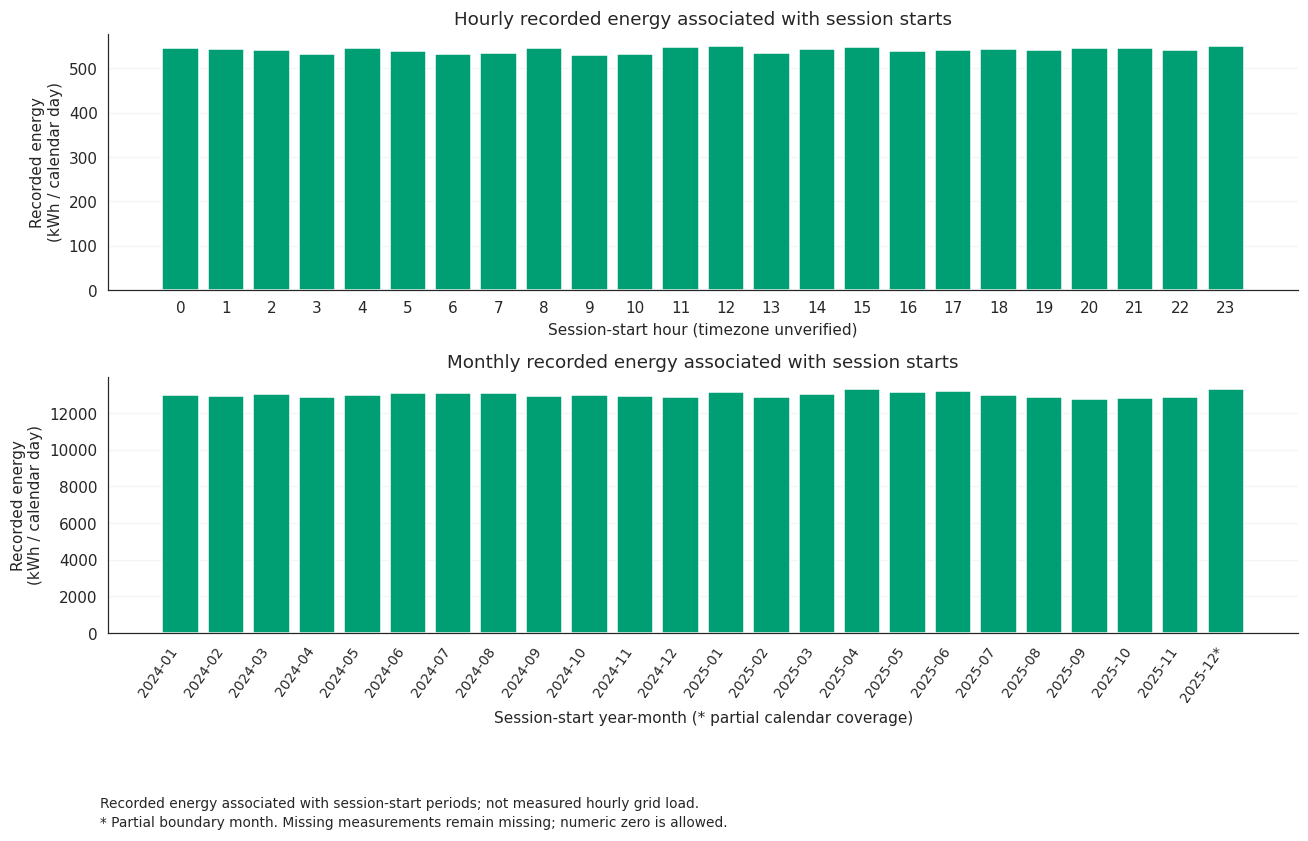

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].bar(hourly.Charging_Hour, hourly.avg_recorded_energy_per_day_kwh, color=GREEN)
axes[0].set_xticks(range(24))
axes[0].set_xlabel("Session-start hour (timezone unverified)")
axes[0].set_title("Hourly recorded energy associated with session starts")
axes[1].bar(range(len(monthly)), monthly.avg_recorded_energy_per_day_kwh, color=GREEN)
month_ticks(axes[1], monthly)
axes[1].set_title("Monthly recorded energy associated with session starts")
for ax in axes:
    style_axis(ax, "Recorded energy\n(kWh / calendar day)")
show_inline(fig, ENERGY_NOTE + "\n* Partial boundary month. Missing measurements remain missing; numeric zero is allowed.")

**Findings and limitations:** All 200,000 values pass basic numeric energy validity: total 9,493,219.61 kWh, or 47.47 kWh/valid-energy session. Monthly energy/day ranges from 12,780.06 kWh in September 2025 to 13,319.24 kWh in partial December 2025. Numeric validity does not establish physical plausibility, equipment ratings or active charging duration.

## 7. Energy sensitivity and retained sample

**Question:** How does excluding plausibility-flagged sessions change recorded-energy summaries and sample coverage? **Metric:** baseline versus retained energy per unchanged calendar day; a separate panel shows retained valid-energy session counts.

The existing analysis excludes the **union** of energy-above-battery-capacity and energy-above-nominal-charger-energy flags. Their overlap is counted once. Blank flags mean not evaluable, not physically verified. The scenario is not corrected/ground-truth data, and baseline demand never changes.

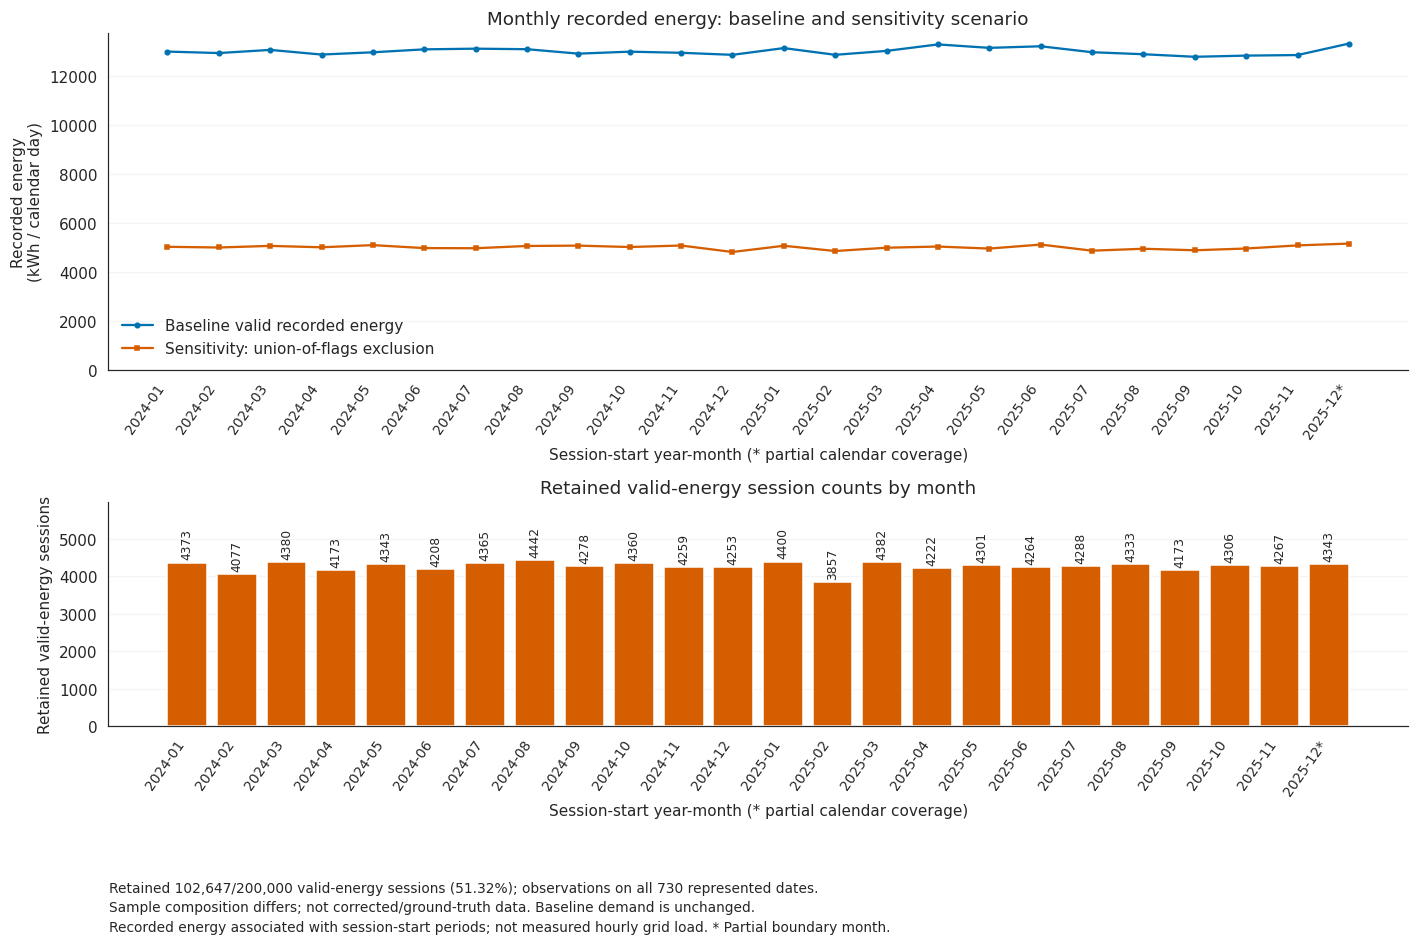

In [8]:
sensitivity = tables["monthly_energy_sensitivity"]
month_positions = range(len(sensitivity))
fig, axes = plt.subplots(2, 1, figsize=(13, 9), gridspec_kw={"height_ratios": [1.5, 1]})
# These are existing verified per-calendar-day summaries, not new exclusions.
axes[0].plot(month_positions, monthly.avg_recorded_energy_per_day_kwh,
             color=BLUE, marker="o", markersize=3, label="Baseline valid recorded energy")
axes[0].plot(month_positions, sensitivity.retained_avg_recorded_energy_per_calendar_day_kwh,
             color=ORANGE, marker="s", markersize=3, label="Sensitivity: union-of-flags exclusion")
axes[0].set_title("Monthly recorded energy: baseline and sensitivity scenario")
style_axis(axes[0], "Recorded energy\n(kWh / calendar day)")
axes[0].legend(frameon=False, loc="lower left")
bars = axes[1].bar(month_positions, sensitivity.retained_valid_energy_session_count, color=ORANGE)
axes[1].bar_label(bars, fmt="%.0f", padding=2, rotation=90, fontsize=8)
axes[1].set_ylim(0, sensitivity.retained_valid_energy_session_count.max() * 1.35)
axes[1].set_title("Retained valid-energy session counts by month")
style_axis(axes[1], "Retained valid-energy sessions")
for ax in axes:
    month_ticks(ax, sensitivity)
show_inline(fig, "Retained 102,647/200,000 valid-energy sessions (51.32%); observations on all 730 represented dates.\n"
                 "Sample composition differs; not corrected/ground-truth data. Baseline demand is unchanged.\n"
                 + ENERGY_NOTE + " * Partial boundary month.")

**Findings and limitations:** Capacity concerns flag 49,101 sessions, nominal charger-energy concerns 71,740, and both 23,488; their union is 97,353. Sensitivity retains 102,647 sessions (51.32%) and 3,648,439.11 kWh (38.43% of baseline). Retained energy is observed on all 730 calendar dates, which does not verify full collection. Exclusions can change sample composition; field definitions, losses and equipment information remain unverified.

## Handoff and caveats

Preserve the inclusive calendar assumption, separate year-months, valid-energy coverage, and baseline/sensitivity distinction. Member 4 should use session-level data plus a date table for interactive measures and these Python results as matching-filter reference checks. Fixed aggregate averages should not be reused under incompatible filters.

Source/licence, collection methodology and timezone remain unverified. Station names/locations have inconsistent mappings; no geographic recommendations follow. True utilization requires reliable capacity/availability data, and busiest starts are not proof of congestion. No station/queue analysis, Power BI or final individual write-up is performed here. See `docs/demand_methodology.md` and `docs/member2_findings.md`.

In [9]:
assert protected_hashes == {path: file_hash(path) for path in protected}
assert not plt.get_fignums(), "Close every figure after its inline display."
print("Inputs and verified summaries unchanged. Seven inline figures displayed; none saved or loaded from image files.")

Inputs and verified summaries unchanged. Seven inline figures displayed; none saved or loaded from image files.
